# Docling: line cells vs. paragraph blocks

This notebook visualizes exactly what `pdf_reader._extract_via_docling()` does (see `Pray/pdf_reader.py:1275-1397`), so you can *see* the bug it was written to avoid and confirm the mechanism is what we described.

**The mechanism, in short:**

1. Docling converts the PDF with its own OCR backend (`DocumentConverter().convert(...)`).
2. For each page, we read `page.cells` -- Docling's **raw OCR line cells**. Each cell is one physically-detected text line with its own tight bounding box (falls back to `parsed_page.textline_cells` if `page.cells` is empty, and only falls back further to `doc.iterate_items()`'s **paragraph/table blocks** if a page has no line cells at all).
3. Line cells (or block words, on the fallback path) are grouped into visual rows by vertical-center clustering (`_docling_group_lines`) -- the same style of grouping `extract_page_layout_canvas` does for pdfplumber words elsewhere in this module.
4. Each row is laid out on a fixed-width character grid (`_docling_render_canvas`), producing the same kind of 2D ASCII canvas text the rest of the pipeline uses.
5. Pages are joined with the same `PAGE N OF M` markers `extract_full_pdf` emits, so downstream chunking (`llm_extract._split_text_by_page`, `_drop_transport_document_pages`) works unchanged regardless of which OCR tier produced the text.

**Why line cells, not paragraph blocks:** Docling's layout model sometimes clusters several *physically stacked* source lines -- a letterhead, a multi-line address, a two-column Bill-to/Ship-to block -- into ONE paragraph item with a SINGLE bounding box. When that merged box is rendered, every original line collapses onto one output line with no way to recover the line breaks. Confirmed real case (see the docstring): `142 Shipping Documents.PDF` -- a company-name + address letterhead, and a two-column Bill-to/Ship-to block, each merged onto a single line under `doc.iterate_items()`. Line cells don't have this problem because each cell IS one physical line already.

Below: the two box sets drawn on the actual page image, then the two text renderings side by side, on that same confirmed-problem file.

## 0. Dependencies

`docling` is **not currently installed** in the `rocky` venv this project uses (checked: `ModuleNotFoundError`). It's a heavy install -- pulls in `torch`, `onnxruntime`, and its own OCR models (first run also downloads model weights). Uncomment and run the cell below once, if you want to actually execute this notebook rather than just read it.

In [ ]:
# !pip install docling docling-core

In [2]:
import sys
from pathlib import Path

PRAY_DIR = Path(r"D:\prashantproject\Pray")
sys.path.insert(0, str(PRAY_DIR))

import statistics
import pdfplumber
import matplotlib.pyplot as plt

import pdf_reader  # the real module -- we call its actual functions below, not copies

# The confirmed real case from _extract_via_docling's own docstring.
# Swap this to any other scanned PDF to inspect it instead.
PDF_PATH = PRAY_DIR / "FILES" / "IMPORT" / "MICROSOFT HYD IMP" / "MICROSOFT HYD IMP" / "CI[0].PDF"
PAGE_NUM = 0  # 0-indexed page to visualize

assert PDF_PATH.exists(), f"not found: {PDF_PATH}"

## 1. Run the real pipeline function

This is the actual output `extract_text(pdf_path, force_docling=True)` would use -- no re-implementation, straight from `pdf_reader._extract_via_docling`.

In [3]:
pipeline_text, pipeline_seconds = pdf_reader._extract_via_docling(PDF_PATH)
print(f"Docling pipeline took {pipeline_seconds}s, produced {len(pipeline_text)} chars\n")
print(pipeline_text[:3000])

[INFO] 2026-10-13 13:47:23,477 [RapidOCR] base.py:23: Using engine_name: onnxruntime
[INFO] 2026-10-13 13:47:23,493 [RapidOCR] download_file.py:60: File exists and is valid: C:\Users\T106\anaconda3\envs\topstar\Lib\site-packages\rapidocr\models\PP-OCRv6_det_small.onnx
[INFO] 2026-10-13 13:47:23,494 [RapidOCR] main.py:63: Using C:\Users\T106\anaconda3\envs\topstar\Lib\site-packages\rapidocr\models\PP-OCRv6_det_small.onnx
[INFO] 2026-10-13 13:47:23,561 [RapidOCR] base.py:23: Using engine_name: onnxruntime
[INFO] 2026-10-13 13:47:23,565 [RapidOCR] download_file.py:60: File exists and is valid: C:\Users\T106\anaconda3\envs\topstar\Lib\site-packages\rapidocr\models\ch_ppocr_mobile_v2.0_cls_mobile.onnx
[INFO] 2026-10-13 13:47:23,566 [RapidOCR] main.py:63: Using C:\Users\T106\anaconda3\envs\topstar\Lib\site-packages\rapidocr\models\ch_ppocr_mobile_v2.0_cls_mobile.onnx
[INFO] 2026-10-13 13:47:23,604 [RapidOCR] base.py:23: Using engine_name: onnxruntime
[INFO] 2026-10-13 13:47:23,637 [RapidOCR]

Docling pipeline took 18.66s, produced 3791 chars

=================================== PAGE 1 OF 1 (CI[0].PDF) ===================================
   350 Meadowlands Parkway,Secaucus,NJ,US,07094                                                                 TEL:201-559-1000 FAX:201-559-1004
                                              COMMERCIAL INVOICE # 7008455
    SHIPPER & EXPORTER: ZT GROUP INT'L INC. DBA ZT SYSTEMS 350 MEADOWLANDS PKWY. SECAUCUS NJ 07094
                                            IMPORTER & SOLD TO:                                        SHIP TO:
                                            Microsoft Corporation India Pvt. Ltd DLF Downtown Level 8 Block 2 DLF Phase - 3 Sector - 25A Gurugram 122002
                                                                                                       MICROSOFT CORP.(INDIA) PRIVATE LTD - HYD11 LANDMAR:NEAR ESTER FILMTECH LTD ON NAGARGUDA PLOT#10 TSIIC CHANDANVELLY
                                                  

## 2. Pull the raw cells/blocks for one page (for the visual overlay)

`_extract_via_docling`'s box-conversion logic (`to_box`/`as_word`) is defined *inside* that function, so it isn't importable directly. The cell below mirrors it exactly (same `to_box` scaling, same cell/text filtering) purely so we can draw the boxes on the page image -- the actual TEXT result you should trust is the one from cell above, not this one.

In [6]:
from docling.document_converter import DocumentConverter
from docling_core.types.doc import TableItem

with pdfplumber.open(str(PDF_PATH)) as pdf:
    page_sizes = [(p.width, p.height) for p in pdf.pages]


res = DocumentConverter().convert(str(PDF_PATH))
doc = res.document

print("PAGE_NUM:", PAGE_NUM, "| pdfplumber pages:", len(page_sizes))
print("res.pages:", len(res.pages), [p.page_no for p in res.pages][:10])
print("doc.pages keys:", sorted(doc.pages.keys())[:10])



def to_box(bbox, page_no):
    """Mirrors pdf_reader._extract_via_docling's to_box: Docling boxes come
    in Docling's own page-size space (often the DPI it OCR'd at, not the
    PDF's own point size) -- rescale to pdfplumber's coordinate space so the
    boxes line up with the page image we draw them on below."""
    dp_size = doc.pages[page_no].size
    pw, ph = page_sizes[page_no - 1] if page_no - 1 < len(page_sizes) else (dp_size.width, dp_size.height)
    b = bbox.to_top_left_origin(page_height=dp_size.height)
    sx, sy = pw / dp_size.width, ph / dp_size.height
    return (b.l * sx, b.t * sy, b.r * sx, b.b * sy)


def as_word(box, text):
    return {"x0": box[0], "x1": box[2], "top": box[1], "bottom": box[3], "text": text}


pn = PAGE_NUM + 1  # Docling pages are 1-indexed

# -- raw OCR LINE cells (what the live pipeline actually uses) --
p = next((p for p in res.pages if p.page_no == pn), None) \
    or next((p for p in res.pages if p.page_no + 1 == pn), None)
try:
    cells = list(p.cells)
except Exception:
    cells = []
if not cells:
    parsed = getattr(p, "parsed_page", None)
    cells = list(getattr(parsed, "textline_cells", None) or [])

line_words = []
for c in cells:
    txt = (getattr(c, "text", "") or "").strip()
    if not txt:
        continue
    try:
        box = to_box(c.rect.to_bounding_box(), pn)
    except Exception:
        continue
    line_words.append(as_word(box, txt))

# -- paragraph/table BLOCKS (doc.iterate_items(), the layout-model path) --
block_words = []
for item, _level in doc.iterate_items():
    if not getattr(item, "prov", None):
        continue
    if isinstance(item, TableItem):
        if item.prov[0].page_no != pn:
            continue
        for c in item.data.table_cells:
            txt = (c.text or "").strip()
            if txt:
                block_words.append(as_word(to_box(c.bbox, pn), txt))
        continue
    text = getattr(item, "text", None)
    if text and text.strip():
        for prov in item.prov:
            if prov.page_no == pn:
                block_words.append(as_word(to_box(prov.bbox, pn), text.strip()))

print(f"page {pn}: {len(line_words)} line cells, {len(block_words)} paragraph/table blocks")

[INFO] 2026-10-13 13:49:47,689 [RapidOCR] base.py:23: Using engine_name: onnxruntime
[INFO] 2026-10-13 13:49:47,698 [RapidOCR] download_file.py:60: File exists and is valid: C:\Users\T106\anaconda3\envs\topstar\Lib\site-packages\rapidocr\models\PP-OCRv6_det_small.onnx
[INFO] 2026-10-13 13:49:47,699 [RapidOCR] main.py:63: Using C:\Users\T106\anaconda3\envs\topstar\Lib\site-packages\rapidocr\models\PP-OCRv6_det_small.onnx
[INFO] 2026-10-13 13:49:47,764 [RapidOCR] base.py:23: Using engine_name: onnxruntime
[INFO] 2026-10-13 13:49:47,766 [RapidOCR] download_file.py:60: File exists and is valid: C:\Users\T106\anaconda3\envs\topstar\Lib\site-packages\rapidocr\models\ch_ppocr_mobile_v2.0_cls_mobile.onnx
[INFO] 2026-10-13 13:49:47,767 [RapidOCR] main.py:63: Using C:\Users\T106\anaconda3\envs\topstar\Lib\site-packages\rapidocr\models\ch_ppocr_mobile_v2.0_cls_mobile.onnx
[INFO] 2026-10-13 13:49:47,809 [RapidOCR] base.py:23: Using engine_name: onnxruntime
[INFO] 2026-10-13 13:49:47,827 [RapidOCR]

PAGE_NUM: 0 | pdfplumber pages: 1
res.pages: 1 [1]
doc.pages keys: [1]
page 1: 0 line cells, 41 paragraph/table blocks


## 3. Draw both box sets on the page image

Green = raw OCR line cells (one box per real text line -- what the pipeline uses). Red = paragraph/table blocks (the layout model's merged groupings -- what the pipeline falls back to only when a page has no line cells). Where you see ONE red box spanning several lines that each have their OWN green box, that's the merge this design avoids.

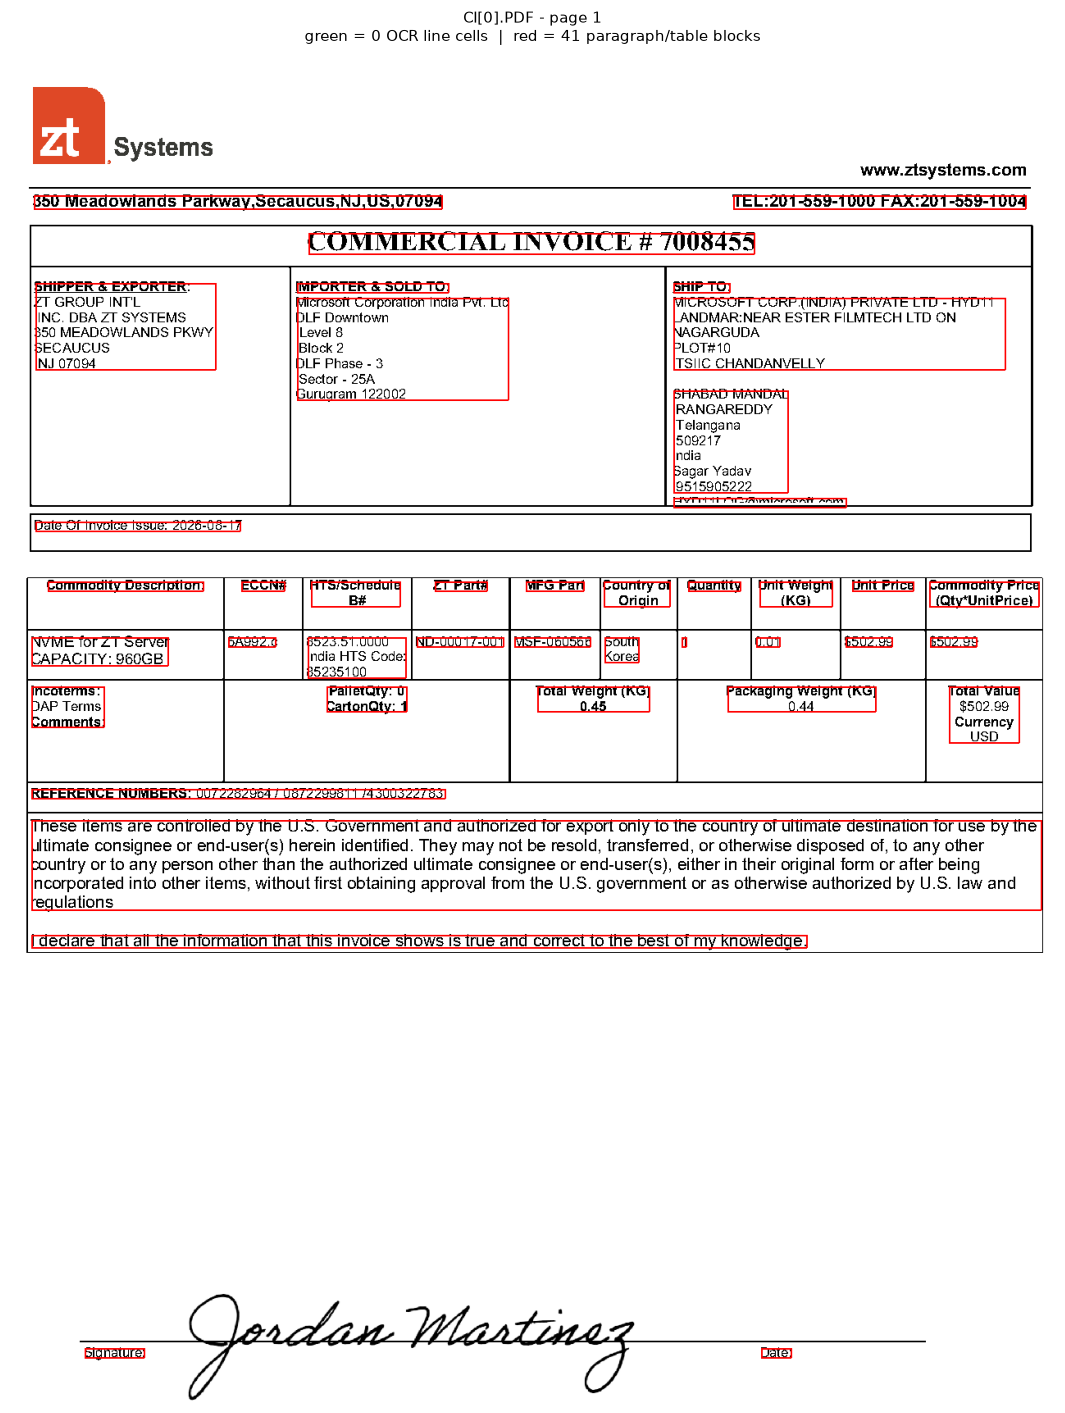

In [7]:
with pdfplumber.open(str(PDF_PATH)) as pdf:
    page = pdf.pages[PAGE_NUM]
    img = page.to_image(resolution=150)
    img = img.draw_rects(
        [{"x0": w["x0"], "x1": w["x1"], "top": w["top"], "bottom": w["bottom"]} for w in block_words],
        stroke="red", stroke_width=2, fill=None,
    )
    img = img.draw_rects(
        [{"x0": w["x0"], "x1": w["x1"], "top": w["top"], "bottom": w["bottom"]} for w in line_words],
        stroke="green", stroke_width=1, fill=None,
    )

    fig, ax = plt.subplots(figsize=(11, 11 * (page.height / page.width)))
    ax.imshow(img.annotated)
    ax.axis("off")
    ax.set_title(
        f"{PDF_PATH.name} - page {PAGE_NUM + 1}\n"
        f"green = {len(line_words)} OCR line cells  |  red = {len(block_words)} paragraph/table blocks",
        fontsize=11,
    )
    plt.tight_layout()
    plt.show()

## 4. Render both as 2D canvas text, side by side

This is the exact grouping + rendering `_extract_via_docling` applies (`_docling_group_lines` then `_docling_render_canvas`, both called unmodified from `pdf_reader`), run once on the line cells and once on the blocks, so you can see the actual text difference the boxes above predict.

In [8]:
def render(words, label):
    if not words:
        print(f"-- {label}: no words on this page --")
        return
    widths = [(w["x1"] - w["x0"]) / len(w["text"]) for w in words if len(w["text"]) > 1]
    char_w = max(round(statistics.median(widths), 2), 1.0) if widths else 4.0
    heights = [w["bottom"] - w["top"] for w in words] or [8.0]
    v_tol = max(2.0, statistics.median(heights) * 0.35)
    body = pdf_reader._docling_render_canvas(words, char_w, v_tol)
    print(f"===== {label} ({len(words)} boxes) =====")
    print(body)
    
    print()


render(line_words, "LINE CELLS (what the pipeline actually uses)")
render(block_words, "PARAGRAPH/TABLE BLOCKS (the fallback path -- watch for merged lines)")

-- LINE CELLS (what the pipeline actually uses): no words on this page --
===== PARAGRAPH/TABLE BLOCKS (the fallback path -- watch for merged lines) (41 boxes) =====
   350 Meadowlands Parkway,Secaucus,NJ,US,07094                                                                 TEL:201-559-1000 FAX:201-559-1004
                                              COMMERCIAL INVOICE # 7008455
    SHIPPER & EXPORTER: ZT GROUP INT'L INC. DBA ZT SYSTEMS 350 MEADOWLANDS PKWY. SECAUCUS NJ 07094
                                            IMPORTER & SOLD TO:                                        SHIP TO:
                                            Microsoft Corporation India Pvt. Ltd DLF Downtown Level 8 Block 2 DLF Phase - 3 Sector - 25A Gurugram 122002
                                                                                                       MICROSOFT CORP.(INDIA) PRIVATE LTD - HYD11 LANDMAR:NEAR ESTER FILMTECH LTD ON NAGARGUDA PLOT#10 TSIIC CHANDANVELLY
                               

## 5. To check a different file

Change `PDF_PATH` (and `PAGE_NUM`) in cell 2 and re-run everything from cell 2 down. `pn = PAGE_NUM + 1` handles the 1-index/0-index mismatch between Docling's pages and pdfplumber's -- no other change needed.